## Imports

Kaggle dataset: https://www.kaggle.com/datasets/gianinamariapetrascu/gamification-students-grades

In [1]:
import warnings

import pandas as pd                 # Data manipulation
import numpy as np                  # Data manipulation
import matplotlib.pyplot as plt     # Visualisation
import seaborn as sns               # Visualisation
from IPython.display import display

# Statistical tests and regression
from scipy import stats
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.stats.diagnostic import het_breuschpagan, linear_reset
from statsmodels.stats.stattools import durbin_watson

#Model Training
from sklearn.model_selection import train_test_split, RepeatedStratifiedKFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression           # Logistic regression
from sklearn.neighbors import KNeighborsClassifier            # K-Nearest Neighbours
from sklearn.tree import DecisionTreeClassifier, export_text  # Decision tree
from sklearn.ensemble import RandomForestClassifier           # Random forest

# Model evaluation
from sklearn.inspection import permutation_importance
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

warnings.filterwarnings("ignore")
plt.rcParams.update({"font.family": "DejaVu Sans", "font.size": 10})
pd.set_option("display.precision", 3)

RANDOM_STATE = 42   # One seed for every random step, so results are reproducible
results = {}        # Every result is collected here; look up any value later, e.g. results["regression_A"]

# Slightly custom rounding method to simply handle missing/unexpected values
def rnd(value, decimals=3):
    if value is None or (isinstance(value, float) and np.isnan(value)):
        return None
    return round(float(value), decimals)

---
## Load Dataset

In [2]:
!kaggle datasets download gianinamariapetrascu/gamification-students-grades

Dataset URL: https://www.kaggle.com/datasets/gianinamariapetrascu/gamification-students-grades
License(s): copyright-authors
100% 1.18k/1.18k [00:00<00:00, 836kB/s]



In [3]:
!unzip gamification-students-grades.zip

Archive:  gamification-students-grades.zip
  inflating: Students_gamification_grades.csv  


In [4]:
df_raw= pd.read_csv('Students_gamification_grades.csv')
df_raw.head(10)

,Student_ID,Practice_Exam,Final_Exam,User,Avg_Grade_Q1,Avg_Grade_Q2,Avg_Grade_Q3,Avg_Grade_Q4,Avg_Grade_Q5,Avg_Grade_Q6,No_access_Q1,No_access_Q2,No_access_Q3,No_access_Q4,No_access_Q5,No_access_Q6
0,1046,9.33,7.98,1,6.00,10.0,10.0,10.0,0.0,8.0,1,1,1,1,0,1
1,1048,2.89,6.49,0,0.00,0.0,0.0,0.0,0.0,0.0,0,0,0,0,0,0
2,1050,7.67,6.90,1,9.00,10.0,10.0,10.0,10.0,10.0,1,1,1,1,1,1
3,1052,4.97,7.69,1,6.00,9.0,5.0,4.0,9.0,4.0,2,2,2,1,1,2
4,1054,3.89,7.78,1,9.33,10.0,10.0,10.0,10.0,10.0,12,1,1,1,1,1
5,1056,4.75,6.02,1,7.67,8.0,9.0,10.0,6.0,6.0,3,2,2,2,2,2
6,1058,NaN,6.02,1,8.00,5.0,6.5,8.0,3.0,7.0,2,2,2,2,1,2
7,1060,NaN,3.98,0,0.00,0.0,0.0,0.0,0.0,0.0,0,0,0,0,0,0
8,1062,NaN,3.96,0,0.00,0.0,0.0,0.0,0.0,0.0,0,0,0,0,0,0
9,1064,5.57,7.64,1,8.50,8.0,8.0,10.0,10.0,9.5,2,1,2,4,2,2


In [5]:
print(f"Full dataset shape: {df_raw.shape}")

Full dataset shape: (69, 16)


In [6]:

print(f"Columns: {df_raw.columns.tolist()}")

Columns: ['Student_ID', 'Practice_Exam', 'Final_Exam', 'User', 'Avg_Grade_Q1', 'Avg_Grade_Q2', 'Avg_Grade_Q3', 'Avg_Grade_Q4', 'Avg_Grade_Q5', 'Avg_Grade_Q6', 'No_access_Q1', 'No_access_Q2', 'No_access_Q3', 'No_access_Q4', 'No_access_Q5', 'No_access_Q6']


- Practice_Exam: Exam Grades before using the gamified app ( null values = the student did not take the exam)
- Final_Exam: Exam Grades after using the gamified app
- User: 1 - user 0 - non-user
- Avg_Grade_Q1: Average grade for Quiz 1 (PCA)
- Avg_Grade_Q2: Average grade for Quiz 2 (Canonical Analysis)
- Avg_Grade_Q3: Average grade for Quiz 3 (Cluster Analysis)
- Avg_Grade_Q4: Average grade for Quiz 4 (Correspondence Analysis)
- Avg_Grade_Q5: Average grade for Quiz 5 (Discriminant Analysis)
- Avg_Grade_Q6: Average grade for Quiz 6 (Panel Regression)
- No_access_Q1: Number of submissions for Quiz 1 (PCA)
- No_access_Q2: Number of submissions for Quiz 2 (Canonical Analysis)
- No_access_Q3: Number of submissions for Quiz 3 (Cluster Analysis)
- No_access_Q4: Number of submissions for Quiz 4 (Correspondence Analysis)
- No_access_Q5: Number of submissions for Quiz 5 (Discriminant Analysis)
- No_access_Q6: Number of submissions for Quiz 6 (Panel Regression)

In [7]:
# Column groups used throughout the notebook
grade_cols = [f"Avg_Grade_Q{i}" for i in range(1, 7)]    # Average grade per quiz
access_cols = [f"No_access_Q{i}" for i in range(1, 7)]   # Number of submissions per quiz

In [8]:
print(f"Data Types: {df_raw.dtypes}")

Data Types: Student_ID         int64
Practice_Exam    float64
Final_Exam       float64
User               int64
Avg_Grade_Q1     float64
Avg_Grade_Q2     float64
Avg_Grade_Q3     float64
Avg_Grade_Q4     float64
Avg_Grade_Q5     float64
Avg_Grade_Q6     float64
No_access_Q1       int64
No_access_Q2       int64
No_access_Q3       int64
No_access_Q4       int64
No_access_Q5       int64
No_access_Q6       int64
dtype: object


In [9]:
print(f"\nMissing values:\n{df_raw.isnull().sum()}")


Missing values:
Student_ID        0
Practice_Exam    12
Final_Exam        0
User              0
Avg_Grade_Q1      0
Avg_Grade_Q2      0
Avg_Grade_Q3      0
Avg_Grade_Q4      0
Avg_Grade_Q5      0
Avg_Grade_Q6      0
No_access_Q1      0
No_access_Q2      0
No_access_Q3      0
No_access_Q4      0
No_access_Q5      0
No_access_Q6      0
dtype: int64


12 students did not take the practice exam before using the gamified app (3 users, 9 non-users). Their improvement from practice to final can't be measured.

These records are **not** removed from the dataset, because they still have a final exam grade and quiz activity. Instead, each analysis that needs `Practice_Exam` drops them on its own (e.g. the paired tests and the regressions). Analyses that only use `Final_Exam` keep all 69 students. For the predictive models, the missing practice grade is filled in with the training-data mean.

In [10]:
print(f"\nDuplicate rows: {df_raw.duplicated().sum()}")
print(f"Duplicate Student_IDs: {df_raw['Student_ID'].duplicated().sum()}")
print(f"Highest submissions on a single quiz: {df_raw[access_cols].values.max()}")


Duplicate rows: 0
Duplicate Student_IDs: 0
Highest submissions on a single quiz: 12


In [11]:
df_raw.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 69 entries, 0 to 68
Data columns (total 16 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Student_ID     69 non-null     int64  
 1   Practice_Exam  57 non-null     float64
 2   Final_Exam     69 non-null     float64
 3   User           69 non-null     int64  
 4   Avg_Grade_Q1   69 non-null     float64
 5   Avg_Grade_Q2   69 non-null     float64
 6   Avg_Grade_Q3   69 non-null     float64
 7   Avg_Grade_Q4   69 non-null     float64
 8   Avg_Grade_Q5   69 non-null     float64
 9   Avg_Grade_Q6   69 non-null     float64
 10  No_access_Q1   69 non-null     int64  
 11  No_access_Q2   69 non-null     int64  
 12  No_access_Q3   69 non-null     int64  
 13  No_access_Q4   69 non-null     int64  
 14  No_access_Q5   69 non-null     int64  
 15  No_access_Q6   69 non-null     int64  
dtypes: float64(8), int64(8)
memory usage: 8.8 KB


---
## Distribution of students

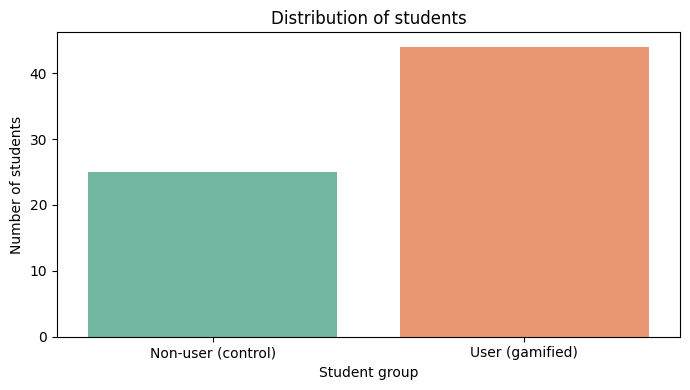

User
1    44
0    25
Name: count, dtype: int64

Class proportions:
User
1    0.638
0    0.362
Name: proportion, dtype: float64


In [12]:
group_names = {0: "Non-user (control)", 1: "User (gamified)"}

plt.figure(figsize=(7, 4))
# Fix: passing palette without hue is deprecated, so the group is assigned to hue
sns.countplot(x="User", hue="User", data=df_raw, palette="Set2", order=[0, 1], legend=False)
plt.title("Distribution of students")
plt.xticks([0, 1], [group_names[0], group_names[1]])
plt.xlabel("Student group")
plt.ylabel("Number of students")
plt.tight_layout()
plt.show()

print(df_raw["User"].value_counts())
print(f"\nClass proportions:\n{df_raw['User'].value_counts(normalize=True).round(3)}")

Control group consists of 36.2% of dataset with the remaining 63.8% making up the students who made use of the gamified application.

---
## Control vs gamified: first look
Split the students into the control group (`User = 0`) and the gamified group (`User = 1`). Both are kept as full DataFrames so any column can be compared.

In [13]:
df_control = df_raw[df_raw["User"] == 0]
df_gamified = df_raw[df_raw["User"] == 1]
print(f"Control: {len(df_control)} students | Gamified: {len(df_gamified)} students")

Control: 25 students | Gamified: 44 students


,mean,sd
Control (User=0),6.254,1.424
Gamified (User=1),7.352,1.345


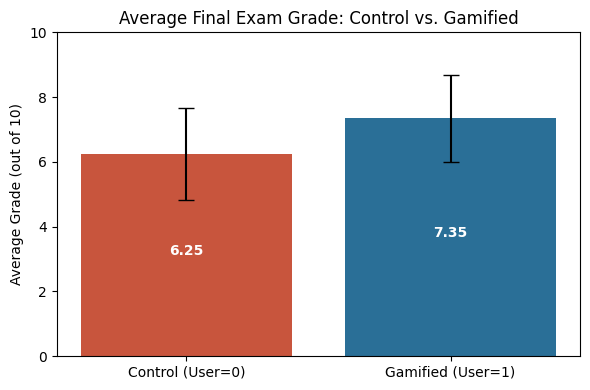

In [14]:
exam_summary = pd.DataFrame({
    "Control (User=0)": [df_control["Final_Exam"].mean(), df_control["Final_Exam"].std()],
    "Gamified (User=1)": [df_gamified["Final_Exam"].mean(), df_gamified["Final_Exam"].std()],
}, index=["mean", "sd"]).T
display(exam_summary)

plt.figure(figsize=(6, 4))
plt.bar(exam_summary.index, exam_summary["mean"], yerr=exam_summary["sd"], capsize=6,
        color=["#c8553d", "#2a6f97"])
for i, mean in enumerate(exam_summary["mean"]):
    plt.text(i, mean / 2, f"{mean:.2f}", ha="center", color="white", fontweight="bold")
plt.title("Average Final Exam Grade: Control vs. Gamified")
plt.ylabel("Average Grade (out of 10)")
plt.ylim(0, 10)
plt.tight_layout()
plt.show()

,Control (User=0),Gamified (User=1)
Practice_Exam,5.154,6.014
Final_Exam,6.754,7.448


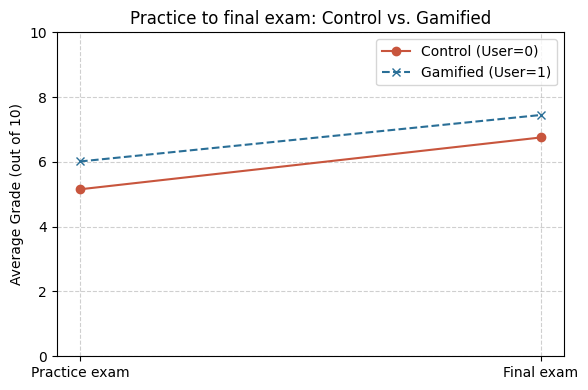

In [15]:
pre_post = pd.DataFrame({
    name: grp.dropna(subset=["Practice_Exam"])[["Practice_Exam", "Final_Exam"]].mean()
    for name, grp in [("Control (User=0)", df_control), ("Gamified (User=1)", df_gamified)]
})
display(pre_post)

plt.figure(figsize=(6, 4))
plt.plot(["Practice exam", "Final exam"], pre_post["Control (User=0)"], label="Control (User=0)",
         color="#c8553d", marker="o")
plt.plot(["Practice exam", "Final exam"], pre_post["Gamified (User=1)"], label="Gamified (User=1)",
         color="#2a6f97", linestyle="--", marker="x")
plt.title("Practice to final exam: Control vs. Gamified")
plt.ylabel("Average Grade (out of 10)")
plt.ylim(0, 10)
plt.legend()
plt.grid(True, linestyle="--", alpha=0.6)
plt.tight_layout()
plt.show()

Control group quiz grades (all zero, they never used the app):


,Avg_Grade_Q1,Avg_Grade_Q2,Avg_Grade_Q3,Avg_Grade_Q4,Avg_Grade_Q5,Avg_Grade_Q6
mean,0.0,0.0,0.0,0.0,0.0,0.0
max,0.0,0.0,0.0,0.0,0.0,0.0


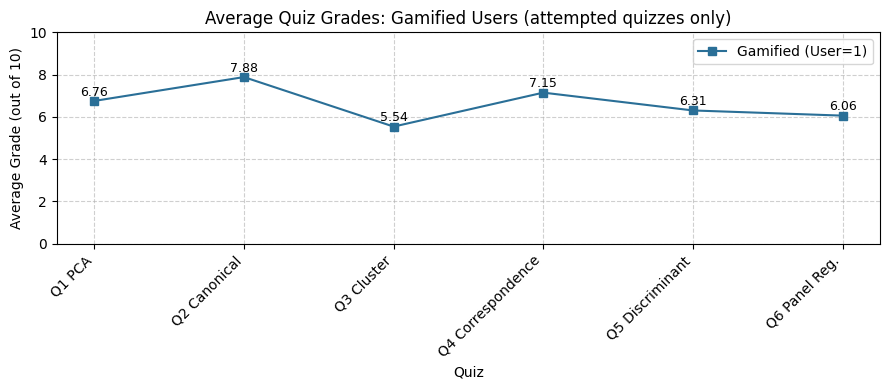

In [16]:
print("Control group quiz grades (all zero, they never used the app):")
display(df_control[grade_cols].describe().loc[["mean", "max"]])

quiz_names = ["Q1 PCA", "Q2 Canonical", "Q3 Cluster", "Q4 Correspondence", "Q5 Discriminant", "Q6 Panel Reg."]
quiz_means_attempted = [df_gamified.loc[df_gamified[a] > 0, g].mean() for g, a in zip(grade_cols, access_cols)]

plt.figure(figsize=(9, 4))
plt.plot(quiz_names, quiz_means_attempted, color="#2a6f97", marker="s", label="Gamified (User=1)")
for x, y in zip(quiz_names, quiz_means_attempted):
    plt.text(x, y + 0.25, f"{y:.2f}", ha="center", fontsize=9)
plt.title("Average Quiz Grades: Gamified Users (attempted quizzes only)")
plt.xlabel("Quiz")
plt.ylabel("Average Grade (out of 10)")
plt.ylim(0, 10)
plt.xticks(rotation=45, ha="right")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.6)
plt.tight_layout()
plt.show()

In [17]:
print("Descriptive statistics for 'Practice_Exam':")
display(df_raw['Practice_Exam'].describe())

Descriptive statistics for 'Practice_Exam':


,Practice_Exam
count,57.000
mean,5.772
std,2.426
min,0.000
25%,4.280
50%,5.870
75%,7.670
max,10.000


In [18]:
print("\nDescriptive statistics for 'Final_Exam':")
display(df_raw['Final_Exam'].describe())


Descriptive statistics for 'Final_Exam':


,Final_Exam
count,69.000
mean,6.954
std,1.464
min,3.960
25%,5.930
50%,6.940
75%,7.940
max,9.720


---
## Feature engineering
Engagement indicators per student, plus binary outcomes for the chi-square tests and the models. A working copy (`df`) is used so `df_raw` stays untouched.

**Tweak:** a quiz grade only counts if the quiz was actually attempted (submissions > 0). Otherwise it is masked, so a 0 doesn't drag the mean down. Non-users therefore get NaN for `Mean_Quiz_Score`.

In [20]:
df = df_raw.copy()

quiz_attempted = df[access_cols] > 0
df["Quizzes_Completed"] = quiz_attempted.sum(axis=1)
df["Total_Attempts"] = df[access_cols].sum(axis=1)
df["Mean_Quiz_Score"] = df[grade_cols].where(quiz_attempted.values).mean(axis=1)
df["Attempts_per_Quiz"] = df["Total_Attempts"] / df["Quizzes_Completed"].replace(0, np.nan)
df["Improvement"] = df["Final_Exam"] - df["Practice_Exam"]

# Binary outcome: median split of the final exam (>= median counts as "high")
final_median = df["Final_Exam"].median()
df["High_Final"] = (df["Final_Exam"] >= final_median).astype(int)
results["median_final"] = rnd(final_median, 2)

# Improved = final beat practice (left as NaN where practice is missing)
df["Improved"] = np.where(df["Practice_Exam"].isna(), np.nan,
                          (df["Final_Exam"] > df["Practice_Exam"]).astype(float))

# Rebuild the group subsets from the working copy so they include the new features
df_gamified = df[df["User"] == 1].copy()
df_control = df[df["User"] == 0].copy()

print(f"Median final exam: {results['median_final']}")
df[["Student_ID", "User", "Quizzes_Completed", "Total_Attempts", "Mean_Quiz_Score",
    "Attempts_per_Quiz", "Improvement", "High_Final", "Improved"]].head(10)

Median final exam: 6.94


,Student_ID,User,Quizzes_Completed,Total_Attempts,Mean_Quiz_Score,Attempts_per_Quiz,Improvement,High_Final,Improved
0,1046,1,5,5,8.800,1.000,-1.35,1,0.0
1,1048,0,0,0,NaN,NaN,3.60,0,1.0
2,1050,1,6,6,9.833,1.000,-0.77,0,0.0
3,1052,1,6,10,6.167,1.667,2.72,1,1.0
4,1054,1,6,17,9.888,2.833,3.89,1,1.0
5,1056,1,6,13,7.778,2.167,1.27,0,1.0
6,1058,1,6,11,6.250,1.833,NaN,0,NaN
7,1060,0,0,0,NaN,NaN,NaN,0,NaN
8,1062,0,0,0,NaN,NaN,NaN,0,NaN
9,1064,1,6,13,9.000,2.167,2.07,1,1.0


**Outlier check (IQR rule)** on total attempts among gamified users. Outliers are flagged only, not removed.

In [21]:
q1, q3 = df_gamified["Total_Attempts"].quantile([.25, .75])
attempt_outliers = df_gamified.loc[df_gamified["Total_Attempts"] > q3 + 1.5 * (q3 - q1),
                                   ["Student_ID", "Total_Attempts"]]
results["attempt_outliers"] = attempt_outliers.values.tolist()
attempt_outliers

,Student_ID,Total_Attempts
4,1054,17
20,1096,22
28,1114,19
43,1148,21
62,1211,19


---
## Descriptive statistics
Summary statistics for the exams (all / users / non-users) and the engagement measures (users only).

In [22]:
def describe_series(series):
    """n, mean, sd, median, IQR, min, max of a series (NaNs dropped)."""
    s = series.dropna()
    return dict(n=int(len(s)), mean=rnd(s.mean(), 2), sd=rnd(s.std(), 2),
                median=rnd(s.median(), 2), iqr=rnd(s.quantile(.75) - s.quantile(.25), 2),
                min=rnd(s.min(), 2), max=rnd(s.max(), 2))


results["descriptives"] = {}
for col in ["Practice_Exam", "Final_Exam", "Improvement"]:
    results["descriptives"][col] = {"all": describe_series(df[col]),
                                    "users": describe_series(df_gamified[col]),
                                    "nonusers": describe_series(df_control[col])}
for col in ["Quizzes_Completed", "Total_Attempts", "Mean_Quiz_Score", "Attempts_per_Quiz"]:
    results["descriptives"][col] = {"users": describe_series(df_gamified[col])}

pd.DataFrame([{"variable": var, "group": grp, **stats_}
              for var, groups in results["descriptives"].items() for grp, stats_ in groups.items()]
             ).set_index(["variable", "group"])

n  mean    sd  median   iqr   min    max
variable          group                                              
Practice_Exam     all       57  5.77  2.43    5.87  3.39  0.00  10.00
                  users     41  6.01  1.99    5.87  2.92  1.39   9.33
                  nonusers  16  5.15  3.28    5.27  4.24  0.00  10.00
Final_Exam        all       69  6.95  1.46    6.94  2.01  3.96   9.72
                  users     44  7.35  1.35    7.46  2.16  5.00   9.72
                  nonusers  25  6.25  1.42    6.49  1.67  3.96   8.87
Improvement       all       57  1.48  2.38    1.30  3.24 -3.24   7.59
                  users     41  1.43  2.07    1.36  2.48 -2.18   5.32
                  nonusers  16  1.60  3.11    0.91  3.57 -3.24   7.59
Quizzes_Completed users     44  5.61  0.99    6.00  0.00  1.00   6.00
Total_Attempts    users     44  9.11  4.60    8.00  4.25  1.00  22.00
Mean_Quiz_Score   users     44  6.60  1.73    6.41  2.20  2.50   9.89
Attempts_per_Quiz users     44  1.59  0.70    1.33  0.58  1.00   3.67

Per-quiz participation, mean grade and mean submissions (attempted quizzes only), plus how many quizzes each user completed.

In [24]:
results["quiz_by_quiz"] = []
for quiz_no, (g, a) in enumerate(zip(grade_cols, access_cols), start=1):
    took_quiz = df_gamified[a] > 0
    results["quiz_by_quiz"].append(dict(quiz=quiz_no, attempted=int(took_quiz.sum()),
                                        mean_grade=rnd(df_gamified.loc[took_quiz, g].mean(), 2),
                                        mean_access=rnd(df_gamified.loc[took_quiz, a].mean(), 2)))
results["completed_dist"] = df_gamified["Quizzes_Completed"].value_counts().sort_index().to_dict()

display(pd.DataFrame(results["quiz_by_quiz"]).set_index("quiz"))
pd.Series(results["completed_dist"], name="users").rename_axis("quizzes completed").to_frame()

,attempted,mean_grade,mean_access
quiz,,,
1,42,6.76,2.29
2,43,7.88,1.53
3,42,5.54,1.57
4,41,7.15,1.44
5,39,6.31,1.49
6,40,6.06,1.40


,users
quizzes completed,
1,1
3,2
5,6
6,35


## Group differences (RQ2): users vs non-users
Welch t-test (doesn't assume equal variances) with Mann-Whitney U as a non-parametric check. Cohen's d uses the pooled SD. Shapiro and Levene are shown so the assumptions can be discussed.

In [23]:
def compare_groups(col):
    users = df.loc[df["User"] == 1, col].dropna()
    nonusers = df.loc[df["User"] == 0, col].dropna()
    welch = stats.ttest_ind(users, nonusers, equal_var=False)
    mann_whitney = stats.mannwhitneyu(users, nonusers)
    pooled_sd = np.sqrt(((len(users) - 1) * users.var() + (len(nonusers) - 1) * nonusers.var())
                        / (len(users) + len(nonusers) - 2))
    return dict(n_users=len(users), n_non=len(nonusers),
                t=rnd(welch.statistic), p=rnd(welch.pvalue, 4),
                U=rnd(mann_whitney.statistic, 1), p_mw=rnd(mann_whitney.pvalue, 4),
                cohens_d=rnd((users.mean() - nonusers.mean()) / pooled_sd),
                diff=rnd(users.mean() - nonusers.mean(), 2),
                shapiro_users=rnd(stats.shapiro(users).pvalue, 4),
                shapiro_non=rnd(stats.shapiro(nonusers).pvalue, 4),
                levene_p=rnd(stats.levene(users, nonusers).pvalue, 4))


results["group_tests"] = {col: compare_groups(col) for col in ["Final_Exam", "Practice_Exam", "Improvement"]}

# Point-biserial correlation = Pearson r between the 0/1 group and the final exam
r, p = stats.pearsonr(df["User"], df["Final_Exam"])
results["pointbiserial_user_final"] = dict(r=rnd(r), p=rnd(p, 4))

display(pd.DataFrame(results["group_tests"]).T)
print("Point-biserial (User vs Final):", results["pointbiserial_user_final"])

,n_users,n_non,t,p,U,p_mw,cohens_d,diff,shapiro_users,shapiro_non,levene_p
Final_Exam,44.0,25.0,3.142,0.003,767.5,0.007,0.800,1.10,0.130,0.267,0.975
Practice_Exam,41.0,16.0,0.978,0.340,379.5,0.365,0.356,0.86,0.355,0.409,0.004
Improvement,41.0,16.0,-0.197,0.846,344.0,0.783,-0.069,-0.17,0.244,0.318,0.118


Point-biserial (User vs Final): {'r': 0.363, 'p': 0.0021}


**Within-group change from practice to final:** paired t-test plus Wilcoxon signed-rank. Only students with a practice grade are included.

In [25]:
results["paired_tests"] = {}
for group_name, group_df in [("users", df_gamified), ("nonusers", df_control)]:
    with_practice = group_df.dropna(subset=["Practice_Exam"])
    paired_t = stats.ttest_rel(with_practice["Final_Exam"], with_practice["Practice_Exam"])
    wilcoxon = stats.wilcoxon(with_practice["Final_Exam"], with_practice["Practice_Exam"])
    results["paired_tests"][group_name] = dict(
        n=len(with_practice), t=rnd(paired_t.statistic), p=rnd(paired_t.pvalue, 4),
        wilcoxon_p=rnd(wilcoxon.pvalue, 4),
        mean_gain=rnd((with_practice["Final_Exam"] - with_practice["Practice_Exam"]).mean(), 2))
pd.DataFrame(results["paired_tests"]).T

,n,t,p,wilcoxon_p,mean_gain
users,41.0,4.444,1.000e-04,1.000e-04,1.43
nonusers,16.0,2.057,5.750e-02,1.046e-01,1.60


## Correlations (RQ1): engagement vs outcomes, gamified users only
Pearson and Spearman side by side (Spearman handles the skew in attempts). Pairwise deletion: each pair uses every row where both values exist.

In [26]:
engagement_cols = ["Quizzes_Completed", "Total_Attempts", "Attempts_per_Quiz", "Mean_Quiz_Score"]
corr_cols = ["Final_Exam", "Practice_Exam"] + engagement_cols

results["corr_final"] = {}
for col in corr_cols[1:]:
    pair = df_gamified[["Final_Exam", col]].dropna()
    r, p = stats.pearsonr(pair["Final_Exam"], pair[col])
    rho, p_rho = stats.spearmanr(pair["Final_Exam"], pair[col])
    results["corr_final"][col] = dict(n=len(pair), r=rnd(r), p=rnd(p, 4), rho=rnd(rho), p_rho=rnd(p_rho, 4))

results["corr_improvement"] = {}
for col in engagement_cols:
    pair = df_gamified[["Improvement", col]].dropna()
    r, p = stats.pearsonr(pair["Improvement"], pair[col])
    results["corr_improvement"][col] = dict(n=len(pair), r=rnd(r), p=rnd(p, 4))

# Inter-correlations among engagement measures (multicollinearity check)
pearson_r = lambda a, b: rnd(stats.pearsonr(df_gamified[a], df_gamified[b])[0])
results["corr_engagement"] = dict(
    completed_vs_attempts=pearson_r("Quizzes_Completed", "Total_Attempts"),
    completed_vs_score=pearson_r("Quizzes_Completed", "Mean_Quiz_Score"),
    attempts_vs_score=pearson_r("Total_Attempts", "Mean_Quiz_Score"))

print("Correlation with Final exam:")
display(pd.DataFrame(results["corr_final"]).T)
print("Correlation with Improvement:")
display(pd.DataFrame(results["corr_improvement"]).T)
print("Engagement inter-correlations:", results["corr_engagement"])

Correlation with Final exam:


,n,r,p,rho,p_rho
Practice_Exam,41.0,0.283,0.073,0.285,0.071
Quizzes_Completed,44.0,-0.199,0.195,-0.024,0.878
Total_Attempts,44.0,0.056,0.717,-0.016,0.917
Attempts_per_Quiz,44.0,0.100,0.517,-0.048,0.759
Mean_Quiz_Score,44.0,0.281,0.065,0.346,0.021


Correlation with Improvement:


,n,r,p
Quizzes_Completed,41.0,-0.075,0.643
Total_Attempts,41.0,0.097,0.548
Attempts_per_Quiz,41.0,0.117,0.465
Mean_Quiz_Score,41.0,0.190,0.235


Engagement inter-correlations: {'completed_vs_attempts': 0.478, 'completed_vs_score': 0.093, 'attempts_vs_score': 0.28}


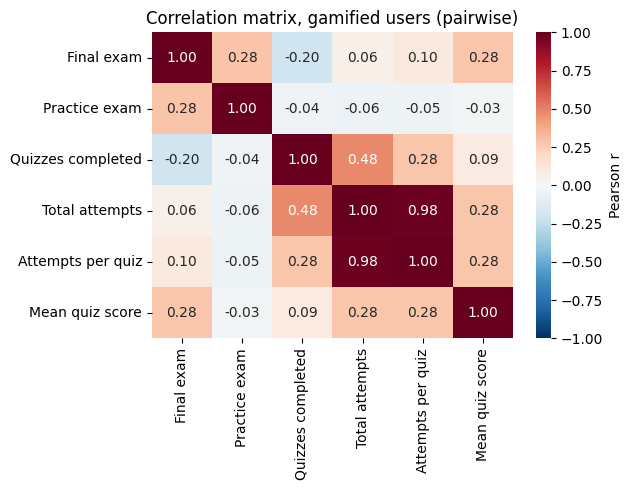

In [27]:
labels = ["Final exam", "Practice exam", "Quizzes completed", "Total attempts",
          "Attempts per quiz", "Mean quiz score"]
plt.figure(figsize=(6.4, 5))
sns.heatmap(df_gamified[corr_cols].corr(), annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1,
            xticklabels=labels, yticklabels=labels, cbar_kws={"label": "Pearson r"})
plt.title("Correlation matrix, gamified users (pairwise)")
plt.tight_layout()
plt.show()

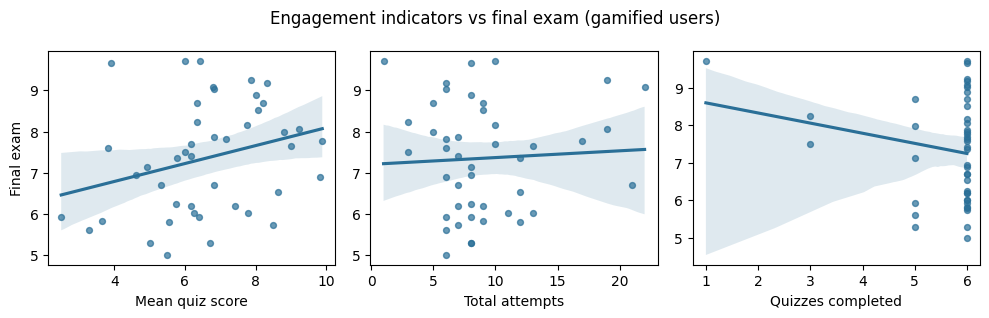

In [28]:
fig, axes = plt.subplots(1, 3, figsize=(10, 3.2))
for i, (col, label) in enumerate([("Mean_Quiz_Score", "Mean quiz score"),
                                  ("Total_Attempts", "Total attempts"),
                                  ("Quizzes_Completed", "Quizzes completed")]):
    sns.regplot(data=df_gamified, x=col, y="Final_Exam", ax=axes[i], color="#2a6f97",
                scatter_kws=dict(s=18, alpha=.7))
    axes[i].set(xlabel=label, ylabel="Final exam" if i == 0 else "")
plt.suptitle("Engagement indicators vs final exam (gamified users)")
plt.tight_layout()
plt.show()

## Regression (OLS)
- **Model A:** does app use predict the final exam once the practice score is held constant? (all students)
- **Model B:** among users, do the engagement indicators add anything beyond the practice score?

Reported for each model: raw b, standardised beta (from z-scored variables), HC3 robust p-values, VIF, Breusch-Pagan (heteroscedasticity), Durbin-Watson, Shapiro on the residuals and RESET (functional form). Listwise deletion: rows missing any model variable are dropped.

In [29]:
def run_ols(data, target, predictors, label):
    data = data[[target] + predictors].dropna()
    z_scored = (data - data.mean()) / data.std()
    X_design = sm.add_constant(data[predictors])
    model = sm.OLS(data[target], X_design).fit()
    model_std = sm.OLS(z_scored[target], sm.add_constant(z_scored[predictors])).fit()
    model_hc3 = sm.OLS(data[target], X_design).fit(cov_type="HC3")
    conf_int = model.conf_int()
    vif = ({x: rnd(variance_inflation_factor(X_design.values, i + 1), 2) for i, x in enumerate(predictors)}
           if len(predictors) > 1 else {predictors[0]: 1.0})
    coefs = {x: dict(b=rnd(model.params[x]), se=rnd(model.bse[x]), beta=rnd(model_std.params[x]),
                     p=rnd(model.pvalues[x], 4), p_hc3=rnd(model_hc3.pvalues[x], 4),
                     ci_low=rnd(conf_int.loc[x, 0]), ci_high=rnd(conf_int.loc[x, 1]), vif=vif[x])
             for x in predictors}
    fit = dict(n=int(model.nobs), r2=rnd(model.rsquared), adj_r2=rnd(model.rsquared_adj),
               F=rnd(model.fvalue, 2), F_p=rnd(model.f_pvalue, 4), const=rnd(model.params["const"]),
               breusch_pagan_p=rnd(het_breuschpagan(model.resid, X_design)[1], 4),
               durbin_watson=rnd(durbin_watson(model.resid), 2),
               shapiro_resid_p=rnd(stats.shapiro(model.resid).pvalue, 4),
               reset_p=rnd(float(linear_reset(model, power=2, use_f=True).pvalue), 4))
    print(label)
    print(fit)
    display(pd.DataFrame(coefs).T)
    return dict(label=label, fit=fit, coefs=coefs)

In [30]:
results["regression_A"] = run_ols(df, "Final_Exam", ["User", "Practice_Exam"],
                                  "Model A, all students: Final ~ User + Practice")

Model A, all students: Final ~ User + Practice
{'n': 57, 'r2': 0.133, 'adj_r2': 0.101, 'F': 4.16, 'F_p': 0.021, 'const': 5.93, 'breusch_pagan_p': 0.8185, 'durbin_watson': 2.23, 'shapiro_resid_p': 0.3561, 'reset_p': 0.1912}


,b,se,beta,p,p_hc3,ci_low,ci_high,vif
User,0.556,0.384,0.186,0.153,0.159,-0.214,1.327,1.03
Practice_Exam,0.160,0.072,0.286,0.030,0.033,0.016,0.304,1.03


`Attempts_per_Quiz` is left out of Model B: it equals `Total_Attempts / Quizzes_Completed`, so including all three would be redundant.

In [31]:
results["regression_B"] = run_ols(df_gamified, "Final_Exam",
                                  ["Practice_Exam", "Quizzes_Completed", "Total_Attempts", "Mean_Quiz_Score"],
                                  "Model B, users: Final ~ Practice + engagement")

Model B, users: Final ~ Practice + engagement
{'n': 41, 'r2': 0.199, 'adj_r2': 0.109, 'F': 2.23, 'F_p': 0.0852, 'const': 6.495, 'breusch_pagan_p': 0.4379, 'durbin_watson': 2.19, 'shapiro_resid_p': 0.5995, 'reset_p': 0.8721}


,b,se,beta,p,p_hc3,ci_low,ci_high,vif
Practice_Exam,0.193,0.101,0.287,0.063,0.055,-0.011,0.398,1.00
Quizzes_Completed,-0.341,0.223,-0.259,0.136,0.189,-0.794,0.113,1.30
Total_Attempts,0.037,0.050,0.130,0.467,0.417,-0.065,0.138,1.40
Mean_Quiz_Score,0.203,0.126,0.252,0.115,0.153,-0.052,0.458,1.09


## Chi-square tests of association
Each 2x2 table is tested three ways: uncorrected chi-square, Yates-corrected, and Fisher's exact (preferred when any expected count is below 5). The effect size is Cramér's V.

In [32]:
def run_chi_square(data, row_var, col_var, label):
    table = pd.crosstab(data[row_var], data[col_var])
    chi2, p, dof, expected = stats.chi2_contingency(table, correction=False)
    chi2_yates, p_yates, _, _ = stats.chi2_contingency(table, correction=True)
    fisher_p = stats.fisher_exact(table.values)[1] if table.shape == (2, 2) else None
    n = table.values.sum()
    summary = dict(n=int(n), chi2=rnd(chi2), p=rnd(p, 4), chi2_yates=rnd(chi2_yates),
                   p_yates=rnd(p_yates, 4), dof=int(dof), min_expected=rnd(expected.min(), 2),
                   fisher_p=rnd(fisher_p, 4),
                   cramers_v=rnd(np.sqrt(chi2 / (n * (min(table.shape) - 1)))))
    print(label)
    display(table)
    print(summary, "\n")
    return dict(label=label, table=table.values.tolist(), **summary)


df_gamified["Full_Completion"] = (df_gamified["Quizzes_Completed"] == 6).astype(int)
df_gamified["High_Attempts"] = (df_gamified["Total_Attempts"] > df_gamified["Total_Attempts"].median()).astype(int)

results["chi_user_high"] = run_chi_square(df, "User", "High_Final", "User x High final (>= median)")
results["chi_user_improved"] = run_chi_square(df.dropna(subset=["Improved"]), "User", "Improved",
                                              "User x Improved (Final > Practice)")
results["chi_full_high"] = run_chi_square(df_gamified, "Full_Completion", "High_Final",
                                          "Users: completed all 6 quizzes x High final")
results["chi_attempts_high"] = run_chi_square(df_gamified, "High_Attempts", "High_Final",
                                              "Users: above-median attempts x High final")

User x High final (>= median)


High_Final,0,1
User,,
0,15,10
1,18,26


{'n': 69, 'chi2': 2.329, 'p': 0.127, 'chi2_yates': 1.626, 'p_yates': 0.2022, 'dof': 1, 'min_expected': 11.96, 'fisher_p': 0.1419, 'cramers_v': 0.184} 

User x Improved (Final > Practice)


Improved,0.0,1.0
User,,
0,5,11
1,10,31


{'n': 57, 'chi2': 0.279, 'p': 0.5972, 'chi2_yates': 0.038, 'p_yates': 0.8464, 'dof': 1, 'min_expected': 4.21, 'fisher_p': 0.7393, 'cramers_v': 0.07} 

Users: completed all 6 quizzes x High final


High_Final,0,1
Full_Completion,,
0,3,6
1,15,20


{'n': 44, 'chi2': 0.269, 'p': 0.6043, 'chi2_yates': 0.019, 'p_yates': 0.8901, 'dof': 1, 'min_expected': 3.68, 'fisher_p': 0.7161, 'cramers_v': 0.078} 

Users: above-median attempts x High final


High_Final,0,1
High_Attempts,,
0,11,15
1,7,11


{'n': 44, 'chi2': 0.051, 'p': 0.8206, 'chi2_yates': 0.0, 'p_yates': 1.0, 'dof': 1, 'min_expected': 7.36, 'fisher_p': 1.0, 'cramers_v': 0.034} 



## Predictive models (RQ3): classifying `High_Final`
**Tweaks:**
- Non-users get `Mean_Quiz_Score = 0` (no quizzes taken) so they stay in the data.
- Missing `Practice_Exam` is mean-imputed **inside** the pipeline, so the imputer only learns from training folds (no leakage).
- Scaling is applied only for the linear and distance-based models (LR, KNN); trees don't need it.
- Trees are kept shallow (max depth 3/4) to limit overfitting with only 69 students.
- The 80/20 test set holds only 14 students, so repeated 5-fold CV (5 folds × 20 repeats = 100 fits) is the main, more stable estimate.

In [33]:
feature_cols = ["User", "Practice_Exam", "Quizzes_Completed", "Total_Attempts", "Mean_Quiz_Score"]
X = df[feature_cols].copy()
X["Mean_Quiz_Score"] = X["Mean_Quiz_Score"].fillna(0)
y = df["High_Final"]


def build_pipeline(model, scale):
    steps = [("impute", SimpleImputer(strategy="mean"))]
    if scale:
        steps.append(("scale", StandardScaler()))
    steps.append(("model", model))
    return Pipeline(steps)


models = {
    "Logistic Regression": build_pipeline(LogisticRegression(max_iter=1000), scale=True),
    "Decision Tree": build_pipeline(DecisionTreeClassifier(max_depth=3, random_state=RANDOM_STATE), scale=False),
    "Random Forest": build_pipeline(RandomForestClassifier(n_estimators=500, max_depth=4,
                                                           random_state=RANDOM_STATE), scale=False),
    "K-Nearest Neighbours": build_pipeline(KNeighborsClassifier(n_neighbors=5), scale=True),
}

# Hold-out split, stratified so both classes are balanced in the test set
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
cv_splitter = RepeatedStratifiedKFold(n_splits=5, n_repeats=20, random_state=RANDOM_STATE)
results["split"] = dict(train=len(X_train), test=len(X_test), test_high_final=int(y_test.sum()))
print(results["split"])

{'train': 55, 'test': 14, 'test_high_final': 7}


### Evaluation: hold-out test set and repeated CV
This cell runs 400 cross-validation fits, so it takes a little while.

In [34]:
results["models"] = {}
for name, pipeline in models.items():
    y_pred = pipeline.fit(X_train, y_train).predict(X_test)
    cv_scores = cross_validate(pipeline, X, y, cv=cv_splitter, scoring=["accuracy", "precision", "recall", "f1"])
    results["models"][name] = dict(
        test_acc=rnd(accuracy_score(y_test, y_pred)),
        test_prec=rnd(precision_score(y_test, y_pred, zero_division=0)),
        test_rec=rnd(recall_score(y_test, y_pred)),
        test_f1=rnd(f1_score(y_test, y_pred)),
        confusion_matrix=confusion_matrix(y_test, y_pred).tolist(),
        cv_acc=rnd(cv_scores["test_accuracy"].mean()), cv_acc_sd=rnd(cv_scores["test_accuracy"].std()),
        cv_f1=rnd(cv_scores["test_f1"].mean()), cv_f1_sd=rnd(cv_scores["test_f1"].std()),
        cv_prec=rnd(cv_scores["test_precision"].mean()), cv_rec=rnd(cv_scores["test_recall"].mean()),
    )

# Reference point: always predicting the majority class
results["baseline_majority_acc"] = rnd(max(y_test.mean(), 1 - y_test.mean()))

display(pd.DataFrame(results["models"]).T)
print("Majority-class baseline accuracy:", results["baseline_majority_acc"])

,test_acc,test_prec,test_rec,test_f1,confusion_matrix,cv_acc,cv_acc_sd,cv_f1,cv_f1_sd,cv_prec,cv_rec
Logistic Regression,0.5,0.5,0.571,0.533,"[[3, 4], [3, 4]]",0.625,0.122,0.645,0.137,0.635,0.679
Decision Tree,0.643,0.75,0.429,0.545,"[[6, 1], [4, 3]]",0.585,0.118,0.583,0.152,0.605,0.591
Random Forest,0.429,0.4,0.286,0.333,"[[4, 3], [5, 2]]",0.605,0.111,0.637,0.117,0.615,0.687
K-Nearest Neighbours,0.5,0.5,0.429,0.462,"[[4, 3], [4, 3]]",0.58,0.118,0.583,0.139,0.61,0.587


Majority-class baseline accuracy: 0.5


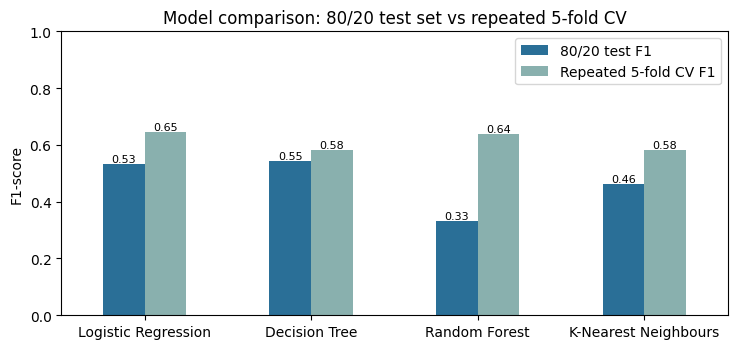

In [35]:
model_f1 = pd.DataFrame({name: {"80/20 test F1": m["test_f1"], "Repeated 5-fold CV F1": m["cv_f1"]}
                         for name, m in results["models"].items()}).T
ax = model_f1.plot.bar(figsize=(7.5, 3.6), color=["#2a6f97", "#89b0ae"], rot=0, ylim=(0, 1))
ax.set(ylabel="F1-score", title="Model comparison: 80/20 test set vs repeated 5-fold CV")
for bars in ax.containers:
    ax.bar_label(bars, fmt="%.2f", fontsize=8)
plt.tight_layout()
plt.show()

---
### Interpretation
Each model is refit on **all** the data to see what drives its predictions. Permutation importance is shown next to the impurity importance because it is less biased.

In [36]:
log_reg = models["Logistic Regression"].fit(X, y)
results["lr_coefs"] = dict(zip(feature_cols, [rnd(c) for c in log_reg.named_steps["model"].coef_[0]]))

random_forest = models["Random Forest"].fit(X, y)
results["rf_importance"] = dict(zip(feature_cols, [rnd(c) for c in random_forest.named_steps["model"].feature_importances_]))
perm = permutation_importance(random_forest, X, y, n_repeats=50, random_state=RANDOM_STATE, scoring="f1")
results["rf_permutation"] = dict(zip(feature_cols, [rnd(c) for c in perm.importances_mean]))

display(pd.DataFrame({"LR coef (standardised)": results["lr_coefs"],
                      "RF impurity importance": results["rf_importance"],
                      "RF permutation importance": results["rf_permutation"]}))

decision_tree = models["Decision Tree"].fit(X, y)
results["tree_rules"] = export_text(decision_tree.named_steps["model"], feature_names=feature_cols)
print("Decision tree rules:\n")
print(results["tree_rules"])

,LR coef (standardised),RF impurity importance,RF permutation importance
User,0.210,0.017,-0.010
Practice_Exam,0.449,0.515,0.227
Quizzes_Completed,-0.607,0.043,0.006
Total_Attempts,0.043,0.141,0.021
Mean_Quiz_Score,0.723,0.284,0.189


Decision tree rules:

|--- Practice_Exam <= 7.80
|   |--- Mean_Quiz_Score <= 3.75
|   |   |--- Practice_Exam <= 0.49
|   |   |   |--- class: 1
|   |   |--- Practice_Exam >  0.49
|   |   |   |--- class: 0
|   |--- Mean_Quiz_Score >  3.75
|   |   |--- Practice_Exam <= 3.54
|   |   |   |--- class: 0
|   |   |--- Practice_Exam >  3.54
|   |   |   |--- class: 1
|--- Practice_Exam >  7.80
|   |--- Mean_Quiz_Score <= 6.27
|   |   |--- Mean_Quiz_Score <= 4.63
|   |   |   |--- class: 1
|   |   |--- Mean_Quiz_Score >  4.63
|   |   |   |--- class: 0
|   |--- Mean_Quiz_Score >  6.27
|   |   |--- class: 1



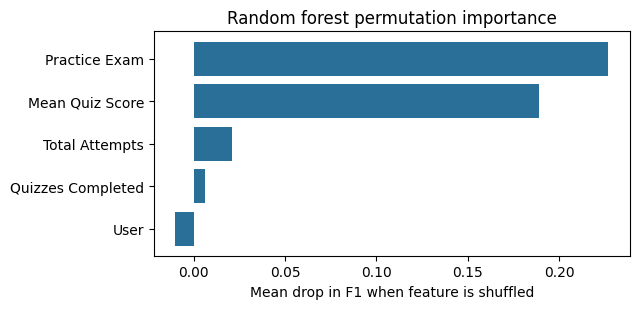

In [37]:
perm_sorted = pd.Series(results["rf_permutation"]).sort_values()
fig, ax = plt.subplots(figsize=(6.5, 3.2))
ax.barh([c.replace("_", " ") for c in perm_sorted.index], perm_sorted.values, color="#2a6f97")
ax.set(xlabel="Mean drop in F1 when feature is shuffled", title="Random forest permutation importance")
plt.tight_layout()
plt.show()

---
### Sensitivity check: without `Practice_Exam`
Shows how much the gamification features predict on their own.

In [38]:
features_no_practice = [c for c in feature_cols if c != "Practice_Exam"]
results["models_no_practice"] = {}
for name, pipeline in models.items():
    cv_scores = cross_validate(pipeline, X[features_no_practice], y, cv=cv_splitter, scoring=["accuracy", "f1"])
    results["models_no_practice"][name] = dict(cv_acc=rnd(cv_scores["test_accuracy"].mean()),
                                               cv_f1=rnd(cv_scores["test_f1"].mean()),
                                               cv_f1_sd=rnd(cv_scores["test_f1"].std()))
pd.DataFrame(results["models_no_practice"]).T

,cv_acc,cv_f1,cv_f1_sd
Logistic Regression,0.578,0.592,0.130
Decision Tree,0.577,0.549,0.198
Random Forest,0.535,0.513,0.135
K-Nearest Neighbours,0.534,0.537,0.143
